# Sharp interactions: learner form and stopping length

This study diagnoses the sharp-interaction component of the large predictive gaps reported in [#493](https://github.com/fcela/mboostrs/issues/493). The historical chooser's +249% excess loss motivates the task; the percentages below come from fresh draws and a different, explicitly frozen experiment. We measure **D11 predictive validity** under scorecard 2.1. Eleven other dimensions remain unmeasured, with no aggregate score.

Each process has eight independent training/test draws. The known-specification track receives the generating variables, functional structure and Gaussian family. The discovery track receives only the development table and response name, plus the fold count, seed and stopping ceiling. Competitors receive data alone in both tracks. The first table reports every method after the repairs.

In [1]:
from pathlib import Path
import sys
import json

ROOT = Path.cwd()
while not (ROOT / "benches").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "python"))

import numpy as np
import pandas as pd
from great_tables import GT
from IPython.display import SVG, display
import mboostrs as mb
from benches.bench_interaction_capacity import DIRECTORY, FORMULAS, draw
from benches.report_interaction_capacity import headline, gap_table, plot_diagnostics, read_document

before = json.loads((DIRECTORY / "baseline/summary.json").read_text())
after = json.loads((DIRECTORY / "recovered/summary.json").read_text())
display(headline(after))

GT(_tbl_data=                  track             method  axis_xor  axis_xor_se  \
0   known_specification     mboostrs_known  0.499867     0.063134   
1   known_specification           catboost  0.508479     0.022442   
2   known_specification           lightgbm  0.693387     0.040455   
3   known_specification            xgboost  0.938448     0.072700   
4   known_specification             histgb  0.795173     0.062273   
5   known_specification              ridge  9.270976     0.017035   
6             discovery  mboostrs_discover  0.480313     0.055015   
7             discovery           catboost  0.508479     0.022442   
8             discovery           lightgbm  0.693387     0.040455   
9             discovery            xgboost  0.938448     0.072700   
10            discovery             histgb  0.795173     0.062273   
11            discovery              ridge  9.270976     0.017035   

    shifted_xor  shifted_xor_se  smooth_product  smooth_product_se  additive  \
0      0.363753        0.023351        0.264775           0.003936  0.254706   
1      0.466479        0.023201        0.331475           0.004243  0.277959   
2      0.542790        0.040600        0.401415           0.006650  0.296946   
3      0.454701        0.024946        0.483176           0.029223  0.281753   
4      0.530755        0.020870        0.398832           0.006554  0.296783   
5      8.724993        0.022107        1.824398           0.015907  1.038837   
6      0.373788        0.024418        0.293156           0.010592  0.255700   
7      0.466479        0.023201        0.331475           0.004243  0.277959   
8      0.542790        0.040600        0.401415           0.006650  0.296946   
9      0.454701        0.024946        0.483176           0.029223  0.281753   
10     0.530755        0.020870        0.398832           0.006554  0.296783   
11     8.724993        0.022107        1.824398           0.015907  1.038837   

    additive_se      null   null_se  
0      0.001685  0.245479  0.002916  
1      0.003760  0.262495  0.003393  
2      0.002700  0.283983  0.003074  
3      0.002989  0.264579  0.003055  
4      0.002337  0.283273  0.003234  
5      0.008369  0.246903  0.003152  
6      0.001782  0.245479  0.002916  
7      0.003760  0.262495  0.003393  
8      0.002700  0.283983  0.003074  
9      0.002989  0.264579  0.003055  
10     0.002337  0.283273  0.003234  
11     0.008369  0.246903  0.003152  , _body=<great_tables._gt_data.Body object at 0x109b4c860>, _boxhead=Boxhead([ColInfo(var='track', type=<ColInfoTypeEnum.row_group: 3>, column_label='track', column_align='left', column_width=None), ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='axis_xor', type=<ColInfoTypeEnum.default: 1>, column_label='MSE', column_align='right', column_width=None), ColInfo(var='axis_xor_se', type=<ColInfoTypeEnum.default: 1>, column_label='SE', column_align='right', column_width=None), ColInfo(var='shifted_xor', type=<ColInfoTypeEnum.default: 1>, column_label='MSE', column_align='right', column_width=None), ColInfo(var='shifted_xor_se', type=<ColInfoTypeEnum.default: 1>, column_label='SE', column_align='right', column_width=None), ColInfo(var='smooth_product', type=<ColInfoTypeEnum.default: 1>, column_label='MSE', column_align='right', column_width=None), ColInfo(var='smooth_product_se', type=<ColInfoTypeEnum.default: 1>, column_label='SE', column_align='right', column_width=None), ColInfo(var='additive', type=<ColInfoTypeEnum.default: 1>, column_label='MSE', column_align='right', column_width=None), ColInfo(var='additive_se', type=<ColInfoTypeEnum.default: 1>, column_label='SE', column_align='right', column_width=None), ColInfo(var='null', type=<ColInfoTypeEnum.default: 1>, column_label='MSE', column_align='right', column_width=None), ColInfo(var='null_se', type=<ColInfoTypeEnum.default: 1>, column_label='SE', column_align='right', column_width=None)]), _stub=

## Experimental settings

The two sharp processes have mean `3*sign(x1)*sign(x2)+x3` and `3*sign(x1-.25)*sign(x2+.15)+x3`. The known depth-three pair tree can represent their step structure; its cut points are estimated from training data. Smooth-product, additive and null processes check whether adding a tree form damages ordinary cases. All five predictors are independent Uniform(-1,1), including two irrelevant predictors; Gaussian noise has standard deviation 0.5 response units. Each draw has 800 development and 2,000 untouched outer-test rows.

The four tree competitors each select among four settings on development rows 600–799 after fitting rows 0–599, then refit the selected setting on all 800 rows. CatBoost varies depth 3/6 and iterations 400/1,000; LightGBM and HistGradientBoosting vary leaves 7/15 and iterations 400/1,000; XGBoost varies depth 2/4 and iterations 400/1,000. Their learning rate is 0.05. Ridge selects alpha 0.1/1/10/100 with training-fitted scaling. The mboostrs tracks use five internal folds and a maximum of 1,600 updates. These searches have unequal cost, so this study cannot support scorecard levels 4 or 5.

The [frozen protocol](interaction_capacity/PROTOCOL.md) specifies the generators, seeds, all consequential arguments, diagnostics, confirmation gate and scoring rule. The table below shows the supplied formulas and sample sizes.

In [2]:
settings = pd.DataFrame([
    {"process": task, "known_formula": formula, "development_rows": 800,
     "outer_test_rows": 2000, "independent_draws": 8}
    for task, formula in FORMULAS.items()
])
display(GT(settings).tab_header(title="Frozen information and sample sizes",
    subtitle="Known formulas only; discovery and competitors receive no formula"))

GT(_tbl_data=          process                                      known_formula  \
0        axis_xor  y ~ btree(x1, x2, maxdepth=3, selection=sse) +...   
1     shifted_xor  y ~ btree(x1, x2, maxdepth=3, selection=sse) +...   
2  smooth_product  y ~ bbs(x1, df=4, knots=8) %X% bbs(x2, df=4, k...   
3        additive                       y ~ bbs(x1, df=4) + bols(x2)   
4            null                                              y ~ 1   

   development_rows  outer_test_rows  independent_draws  
0               800             2000                  8  
1               800             2000                  8  
2               800             2000                  8  
3               800             2000                  8  
4               800             2000                  8  , _body=<great_tables._gt_data.Body object at 0x10e28c590>, _boxhead=Boxhead([ColInfo(var='process', type=<ColInfoTypeEnum.default: 1>, column_label='process', column_align='left', column_width=None), ColInfo(var='known_formula', type=<ColInfoTypeEnum.default: 1>, column_label='known_formula', column_align='left', column_width=None), ColInfo(var='development_rows', type=<ColInfoTypeEnum.default: 1>, column_label='development_rows', column_align='right', column_width=None), ColInfo(var='outer_test_rows', type=<ColInfoTypeEnum.default: 1>, column_label='outer_test_rows', column_align='right', column_width=None), ColInfo(var='independent_draws', type=<ColInfoTypeEnum.default: 1>, column_label='independent_draws', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x1107f6c60>, _spanners=Spanners([]), _heading=Heading(title='Frozen information and sample sizes', subtitle='Known formulas only; discovery and competitors receive no formula', preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x113995a00>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x113996a80>, _source_notes=[], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x113996ab0>, _formats=[], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_

## Public fitting calls

The following calls reproduce axis-boundary replicate 2 on the final implementation. This draw illustrates the diagnosed main-effect omission. `score="mse"` selects response-scale squared error; `max_mstop=1600` is a resource ceiling, not a convergence guarantee. Discovery infers the family and chooses terms from the development data. The prediction comparison uses rows excluded from fitting and tuning; this demonstration repeats a measured draw and adds no independent evidence.

In [3]:
train, test, truth = draw("axis_xor", 2)
known = mb.tune_mstop(FORMULAS["axis_xor"], train,
    family=mb.Gaussian(), folds=5, start=100, max_mstop=1600,
    nu=.1, seed=2, score="mse")
found = mb.discover(train, "y", folds=5, max_mstop=1600, seed=2)
newdata = test.drop(columns="y")
known_pred = known.model.predict(newdata, type="response", extrapolation="clip")
found_prediction = found.model.predict(newdata, type="response", extrapolation="clip")
# Gaussian location-scale predictions contain both mu and sigma; score the mean only.
found_pred = found_prediction["mu"] if isinstance(found_prediction, dict) else found_prediction
example = pd.DataFrame([
    {"track": "known specification", "formula": FORMULAS["axis_xor"],
     "MSE": np.mean((known_pred-test.y.to_numpy())**2)},
    {"track": "discovery", "formula": found.formula,
     "MSE": np.mean((found_pred-test.y.to_numpy())**2)},
])
display(GT(example).tab_header(title="One public-API reproduction",
    subtitle="Replicate 2; outer MSE in squared response units; lower is better").fmt_number(columns="MSE", decimals=4))

GT(_tbl_data=                 track                                            formula  \
0  known specification  y ~ btree(x1, x2, maxdepth=3, selection=sse) +...   
1            discovery  bbs(x1, df=2.5, knots=5) + bbs(x2, df=2.5, kno...   

        MSE  
0  0.656533  
1  0.572819  , _body=<great_tables._gt_data.Body object at 0x113a18a10>, _boxhead=Boxhead([ColInfo(var='track', type=<ColInfoTypeEnum.default: 1>, column_label='track', column_align='left', column_width=None), ColInfo(var='formula', type=<ColInfoTypeEnum.default: 1>, column_label='formula', column_align='left', column_width=None), ColInfo(var='MSE', type=<ColInfoTypeEnum.default: 1>, column_label='MSE', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x113a1b230>, _spanners=Spanners([]), _heading=Heading(title='One public-API reproduction', subtitle='Replicate 2; outer MSE in squared response units; lower is better', preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x113a1a9f0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x113a19010>, _source_notes=[], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x113a18c50>, _formats=[<great_tables._gt_data.FormatInfo object at 0x113a1a2d0>], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=True, category='table', type='value', value='#D3D3D3'), table_border_bottom_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_bottom_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_bottom_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_bottom_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_left_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_left_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_left_color=Options

## Competitor tuning example

The CatBoost code below exposes the four-setting choice used by the runner for this same draw. The 200 validation rows select iterations and depth; their responses are not used by the initial 600-row fits. The selected setting is then refitted on all development rows. Outer-test responses never choose the setting. The other named competitors follow the corresponding finite grids stated above.

In [4]:
from catboost import CatBoostRegressor

predictors = train.drop(columns="y")
peer_choices = []
for iterations in (400, 1000):
    for depth in (3, 6):
        parameters = dict(loss_function="RMSE", iterations=iterations, depth=depth,
            learning_rate=.05, verbose=False, random_seed=2, thread_count=1,
            allow_writing_files=False)
        candidate = CatBoostRegressor(**parameters).fit(predictors.iloc[:600], train.y.iloc[:600])
        validation_mse = np.mean((candidate.predict(predictors.iloc[600:])-train.y.iloc[600:].to_numpy())**2)
        peer_choices.append({"parameters": parameters, "validation_mse": float(validation_mse)})
peer_choice = min(peer_choices, key=lambda row: row["validation_mse"])
display(GT(pd.DataFrame([
    {"iterations": row["parameters"]["iterations"], "depth": row["parameters"]["depth"],
     "validation_MSE": row["validation_mse"]} for row in peer_choices
])).tab_header(title="CatBoost validation grid for replicate 2",
    subtitle="200 reserved development rows; MSE in squared response units; lower is better")
    .fmt_number(columns="validation_MSE", decimals=4))

GT(_tbl_data=   iterations  depth  validation_MSE
0         400      3        0.900105
1         400      6        0.585292
2        1000      3        0.696911
3        1000      6        0.600080, _body=<great_tables._gt_data.Body object at 0x11c19d2e0>, _boxhead=Boxhead([ColInfo(var='iterations', type=<ColInfoTypeEnum.default: 1>, column_label='iterations', column_align='right', column_width=None), ColInfo(var='depth', type=<ColInfoTypeEnum.default: 1>, column_label='depth', column_align='right', column_width=None), ColInfo(var='validation_MSE', type=<ColInfoTypeEnum.default: 1>, column_label='validation_MSE', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x11b05ac00>, _spanners=Spanners([]), _heading=Heading(title='CatBoost validation grid for replicate 2', subtitle='200 reserved development rows; MSE in squared response units; lower is better', preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x117f02d20>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x117f02c90>, _source_notes=[], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x11c5d8530>, _formats=[<great_tables._gt_data.FormatInfo object at 0x119a35a00>], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=True, category='table', type='value', value='#D3D3D3'), table_border_bottom_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_bottom_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_bottom_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_bottom_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_left_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_left_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_left_color=OptionsInfo(scss=True, category='table', 

In [5]:
peer = CatBoostRegressor(**peer_choice["parameters"]).fit(predictors, train.y)
peer_prediction = peer.predict(newdata)
from benches.benchmark_contract import data_digest
measured = read_document("recovered_primary")["results"]
peer_record = next(row for row in measured if row.get("task") == "axis_xor"
    and row.get("seed") == 2 and row.get("method") == "catboost")
assert data_digest(np.asarray(peer_prediction)) == peer_record["prediction_digest"]
display(GT(pd.DataFrame([{"method": "CatBoost", "outer_MSE": np.mean((peer_prediction-test.y.to_numpy())**2),
    "iterations": peer_choice["parameters"]["iterations"], "depth": peer_choice["parameters"]["depth"]}]))
    .tab_header(title="Selected CatBoost refit", subtitle="Exact prediction replay of the frozen job; not another independent draw")
    .fmt_number(columns="outer_MSE", decimals=4))

GT(_tbl_data=     method  outer_MSE  iterations  depth
0  CatBoost   0.522021         400      6, _body=<great_tables._gt_data.Body object at 0x11b01c800>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.default: 1>, column_label='method', column_align='left', column_width=None), ColInfo(var='outer_MSE', type=<ColInfoTypeEnum.default: 1>, column_label='outer_MSE', column_align='right', column_width=None), ColInfo(var='iterations', type=<ColInfoTypeEnum.default: 1>, column_label='iterations', column_align='right', column_width=None), ColInfo(var='depth', type=<ColInfoTypeEnum.default: 1>, column_label='depth', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x11b677530>, _spanners=Spanners([]), _heading=Heading(title='Selected CatBoost refit', subtitle='Exact prediction replay of the frozen job; not another independent draw', preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x11c5d9ca0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x11c5d9cd0>, _source_notes=[], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x11c5d9d00>, _formats=[<great_tables._gt_data.FormatInfo object at 0x11c5d9a90>], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=True, category='table', type='value', value='#D3D3D3'), table_border_bottom_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_bottom_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_bottom_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_bottom_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_left_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_left_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_left_color=OptionsInfo(scss=True, category='table', type='value',

## Baseline gaps

The baseline discovers the correct sharp pair but offers only a smooth tensor form. Extending that fixed dictionary and offering a different learner form are separate interventions. Every baseline method was run on the same rows; eight known-null jobs raise a Python exception and stay in the failure denominator. An incomplete cell receives no successful-only mean.

Each reference below is the **retrospective best complete named competitor**, selected by mean outer-test MSE among the four tree methods. The paired Monte Carlo standard error treats that selected winner as fixed; it excludes uncertainty from selecting the winner.

In [6]:
display(gap_table(before))

GT(_tbl_data=                 track            task best_competitor  completed     gap_pct  \
0  known_specification        axis_xor        catboost          8   -1.953436   
1            discovery        axis_xor        catboost          8  329.330873   
2  known_specification     shifted_xor         xgboost          8  -20.011935   
3            discovery     shifted_xor         xgboost          8  425.385206   
4  known_specification  smooth_product        catboost          8  -20.093109   
5            discovery  smooth_product        catboost          8   -2.453122   
6  known_specification        additive        catboost          8   -8.291719   
7            discovery        additive        catboost          8   -7.945109   
8  known_specification            null        catboost          0         NaN   
9            discovery            null        catboost          8   -6.454931   

   gap_se_pct  difference_mse  difference_se within_1pct unresolved_at_2se  
0   11.426653       -0.008612       0.058565        True              True  
1   22.926271        1.643602       0.067012       False             False  
2    2.203476       -0.090948       0.010400        True             False  
3   37.504133        1.878038       0.107099       False             False  
4    1.030621       -0.066700       0.003714        True             False  
5    5.049386       -0.007981       0.016609        True              True  
6    0.864412       -0.023253       0.002750        True             False  
7    0.713367       -0.022259       0.002296        True             False  
8         NaN             NaN            NaN        None              None  
9    0.713580       -0.017016       0.002002        True             False  , _body=<great_tables._gt_data.Body object at 0x11c5d97f0>, _boxhead=Boxhead([ColInfo(var='track', type=<ColInfoTypeEnum.row_group: 3>, column_label='track', column_align='left', column_width=None), ColInfo(var='task', type=<ColInfoTypeEnum.stub: 2>, column_label='task', column_align='left', column_width=None), ColInfo(var='best_competitor', type=<ColInfoTypeEnum.default: 1>, column_label='best_competitor', column_align='left', column_width=None), ColInfo(var='completed', type=<ColInfoTypeEnum.default: 1>, column_label='completed', column_align='right', column_width=None), ColInfo(var='gap_pct', type=<ColInfoTypeEnum.default: 1>, column_label='gap_pct', column_align='right', column_width=None), ColInfo(var='gap_se_pct', type=<ColInfoTypeEnum.default: 1>, column_label='gap_se_pct', column_align='right', column_width=None), ColInfo(var='difference_mse', type=<ColInfoTypeEnum.default: 1>, column_label='difference_mse', column_align='right', column_width=None), ColInfo(var='difference_se', type=<ColInfoTypeEnum.default: 1>, column_label='difference_se', column_align='right', column_width=None), ColInfo(var='within_1pct', type=<ColInfoTypeEnum.default: 1>, column_label='within_1pct', column_align='right', column_width=None), ColInfo(var='unresolved_at_2se', type=<ColInfoTypeEnum.default: 1>, column_label='unresolved_at_2se', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x11c5d8710>, _spanners=Spanners([SpannerInfo(spanner_id='Gap (%)', spanner_level=0, spanner_label='Gap (%)', spanner_units=None, spanner_pattern=None, vars=['gap_pct', 'gap_se_pct'], built=None), SpannerInfo(spanner_id='Paired MSE difference', spanner_level=0, spanner_label='Paired MSE difference', spanner_units=None, spanner_pattern=None, vars=['difference_mse', 'difference_se'], built=None)]), _heading=Heading(title='Paired gap to the strongest complete tree competitor', subtitle='Percent gap and paired Monte Carlo SE; negative favors mboostrs; target at most +1%', preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x11c5da810>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x11c5da5d0>, _source_notes=['The four-tree reference is selected retrosp

## Stopping-length diagnostic

The separate diagnostic keeps a smooth tensor dictionary, data, folds, learning rate and validation criterion fixed, and raises only its stopping ceiling from 1,600 to 6,400. It uses the true pair and linear third effect; it is not the supplied step specification. All 32 diagnostic jobs complete. Their minima remain at the boundary, so the result does not establish numerical convergence or an irreducible approximation floor. It measures the benefit of this finite budget extension.

In [7]:
diagnostic = pd.DataFrame(json.loads((DIRECTORY / "diagnostic_summary.json").read_text()))
display(GT(diagnostic, rowname_col="task").tab_header(
    title="Longer paths with the same smooth dictionary",
    subtitle="Eight paired draws; MSE in squared response units; negative percent change favors 6,400")
    .tab_spanner("Outer MSE", ["mse1600", "mse6400"])
    .tab_spanner("Paired change (%)", ["change_pct", "change_se"])
    .fmt_number(columns=["mse1600", "mse6400"], decimals=3)
    .fmt_number(columns=["change_pct", "change_se"], decimals=2)
    .tab_source_note("SE = sample SD of per-draw percent changes / sqrt(8). Boundary counts are out of eight; no competitor gap is inferred from this oracle-informed diagnostic."))

GT(_tbl_data=          task    status   mse1600   mse6400  change_pct  change_se  \
0     axis_xor  complete  1.993204  1.771829  -11.112968   0.228946   
1  shifted_xor  complete  1.844408  1.560669  -15.376589   0.494304   

   boundary1600  boundary6400  
0             8             8  
1             8             8  , _body=<great_tables._gt_data.Body object at 0x11b01c800>, _boxhead=Boxhead([ColInfo(var='task', type=<ColInfoTypeEnum.stub: 2>, column_label='task', column_align='left', column_width=None), ColInfo(var='status', type=<ColInfoTypeEnum.default: 1>, column_label='status', column_align='left', column_width=None), ColInfo(var='mse1600', type=<ColInfoTypeEnum.default: 1>, column_label='mse1600', column_align='right', column_width=None), ColInfo(var='mse6400', type=<ColInfoTypeEnum.default: 1>, column_label='mse6400', column_align='right', column_width=None), ColInfo(var='change_pct', type=<ColInfoTypeEnum.default: 1>, column_label='change_pct', column_align='right', column_width=None), ColInfo(var='change_se', type=<ColInfoTypeEnum.default: 1>, column_label='change_se', column_align='right', column_width=None), ColInfo(var='boundary1600', type=<ColInfoTypeEnum.default: 1>, column_label='boundary1600', column_align='right', column_width=None), ColInfo(var='boundary6400', type=<ColInfoTypeEnum.default: 1>, column_label='boundary6400', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x11c5da900>, _spanners=Spanners([SpannerInfo(spanner_id='Outer MSE', spanner_level=0, spanner_label='Outer MSE', spanner_units=None, spanner_pattern=None, vars=['mse1600', 'mse6400'], built=None), SpannerInfo(spanner_id='Paired change (%)', spanner_level=0, spanner_label='Paired change (%)', spanner_units=None, spanner_pattern=None, vars=['change_pct', 'change_se'], built=None)]), _heading=Heading(title='Longer paths with the same smooth dictionary', subtitle='Eight paired draws; MSE in squared response units; negative percent change favors 6,400', preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x11c5db170>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x11c5db410>, _source_notes=['SE = sample SD of per-draw percent changes / sqrt(8). Boundary counts are out of eight; no competitor gap is inferred from this oracle-informed diagnostic.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x11c5daed0>, _formats=[<great_tables._gt_data.FormatInfo object at 0x11c5db3e0>, <great_tables._gt_data.FormatInfo object at 0x11c5db350>], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type=

## Enhancements

[Issue #613](https://github.com/fcela/mboostrs/issues/613), repaired in [MR #614](https://github.com/fcela/mboostrs/pull/614), isolates the missing learner-form comparison. After the existing tensor decision, discovery compares a depth-three tree on the same admissible continuous pair with its actual incumbent. A tree replaces that pair's tensor only when its paired out-of-fold decrease exceeds the existing margin, `2*sqrt(log(5)) = 2.54` change standard errors. Rejection, comparison failure or budget refusal preserves the incumbent. The comparison uses the same folds, family, score and 200-update screening budget. All fitting and risk calculations use the existing Rust core.

[Issue #616](https://github.com/fcela/mboostrs/issues/616), repaired in [MR #618](https://github.com/fcela/mboostrs/pull/618), concerns the eight known-null failures. The native response scorer now takes its row count from the observed response, including when there is no learner. An offset-only model is returned directly rather than sliced at a positive grid index. The numerical score routine remains the existing core routine.

[Issue #615](https://github.com/fcela/mboostrs/issues/615) and [MR #617](https://github.com/fcela/mboostrs/pull/617) repair pre-existing guide-size and lint gates found during validation. They make no statistical change.

A selected tree has **no smooth REML effect intervals**. The optional refit refusal stays in the decision log; boosted predictions and contrasts remain available, with no interval on such contrasts. This study measures prediction, not effect inference or false-discovery control.

[Issue #620](https://github.com/fcela/mboostrs/issues/620), repaired in [MR #621](https://github.com/fcela/mboostrs/pull/621), diagnoses a second mechanism. Three of the eight tree-only axis draws dropped the true `x3` main effect before fitting the dominant interaction. The new stage reconsiders missing draft main terms after interactions, in the original draft order, using the same two-SE mean-effect margin and fold design. It retains equivalent existing main terms and records every adoption or rejection.

A `btree` formula term is refitted to the current gradient at each selected boosting step; the fitted model sums these successive trees. Its presence is not evidence that a model contains only one fixed fitted tree. The changes here concern offered learner forms and conditional term selection, rather than adding an ensemble implementation to the core.

## Independent confirmation

The six additional confirmation families and their seeds were frozen before measuring the candidate rule. They use 600 development and 1,600 test rows, Gaussian noise standard deviation 0.6, three folds and a stopping ceiling of 800. The gate requires each family mean after/before MSE ratio at most 1.01 and no increase in null interaction adoption. All 36 old/new fits complete. The final integrated implementation also replays the candidate's predictions exactly on these rows; that replay is not a second independent confirmation.

In [8]:
gate = json.loads((DIRECTORY / "confirmation_gate.json").read_text())
controls = pd.DataFrame(gate["families"]).drop(columns="individual_changes_pct")
display(GT(controls, rowname_col="task").tab_header(
    title="Frozen confirmation gate", subtitle="Six independent draws per family; MSE ratio at most 1.01 required")
    .tab_spanner("Outer MSE", ["before", "after", "ratio"])
    .tab_spanner("Paired percent change", ["change_pct", "change_se"])
    .fmt_number(columns=["before", "after", "ratio"], decimals=3)
    .fmt_number(columns=["change_pct", "change_se"], decimals=2)
    .tab_source_note("Unchanged counts compare prediction hashes. Interaction counts are draws with any adopted interaction. The finite null check is not a false-discovery guarantee; individual changes remain in confirmation_gate.json."))

GT(_tbl_data=      task    before     after     ratio  change_pct  change_se  unchanged  \
0   linear  0.356590  0.356590  1.000000    0.000000   0.000000          6   
1   curved  0.367784  0.367784  1.000000    0.000000   0.000000          6   
2  product  0.398176  0.398176  1.000000    0.000000   0.000000          6   
3   factor  0.409530  0.404908  0.988713   -1.037219   1.037219          5   
4     null  0.348822  0.348822  1.000000    0.000000   0.000000          6   
5     step  1.280161  0.467625  0.365286  -63.467728   1.622632          0   

   before_interactions  after_interactions  
0                    0                   0  
1                    0                   0  
2                    6                   6  
3                    6                   6  
4                    0                   0  
5                    6                   6  , _body=<great_tables._gt_data.Body object at 0x11b01c800>, _boxhead=Boxhead([ColInfo(var='task', type=<ColInfoTypeEnum.stub: 2>, column_label='task', column_align='left', column_width=None), ColInfo(var='before', type=<ColInfoTypeEnum.default: 1>, column_label='before', column_align='right', column_width=None), ColInfo(var='after', type=<ColInfoTypeEnum.default: 1>, column_label='after', column_align='right', column_width=None), ColInfo(var='ratio', type=<ColInfoTypeEnum.default: 1>, column_label='ratio', column_align='right', column_width=None), ColInfo(var='change_pct', type=<ColInfoTypeEnum.default: 1>, column_label='change_pct', column_align='right', column_width=None), ColInfo(var='change_se', type=<ColInfoTypeEnum.default: 1>, column_label='change_se', column_align='right', column_width=None), ColInfo(var='unchanged', type=<ColInfoTypeEnum.default: 1>, column_label='unchanged', column_align='right', column_width=None), ColInfo(var='before_interactions', type=<ColInfoTypeEnum.default: 1>, column_label='before_interactions', column_align='right', column_width=None), ColInfo(var='after_interactions', type=<ColInfoTypeEnum.default: 1>, column_label='after_interactions', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x11c5d8bf0>, _spanners=Spanners([SpannerInfo(spanner_id='Outer MSE', spanner_level=0, spanner_label='Outer MSE', spanner_units=None, spanner_pattern=None, vars=['before', 'after', 'ratio'], built=None), SpannerInfo(spanner_id='Paired percent change', spanner_level=0, spanner_label='Paired percent change', spanner_units=None, spanner_pattern=None, vars=['change_pct', 'change_se'], built=None)]), _heading=Heading(title='Frozen confirmation gate', subtitle='Six independent draws per family; MSE ratio at most 1.01 required', preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x11c5db200>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x11c5d92b0>, _source_notes=['Unchanged counts compare prediction hashes. Interaction counts are draws with any adopted interaction. The finite null check is not a false-discovery guarantee; individual changes remain in confirmation_gate.json.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x11c5d91f0>, _formats=[<great_tables._gt_data.FormatInfo object at 0x11c5da6f0>, <great_tables._gt_data.FormatInfo object at 0x11c5db740>], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=Optio

## Tree-only intermediate phase

The first repair completes all 280 jobs, but axis-boundary discovery still has a +23.48% gap (paired SE 21.91 percentage points) to retrospective CatBoost. The three worst draws omit `x3`. This point misses the one-percent target while remaining unresolved at two SE. The complete intermediate results are retained below; the main-effect recovery rule was not evaluated on its old confirmation draws as though they were fresh.

In [9]:
tree_only = json.loads((DIRECTORY / "after/summary.json").read_text())
display(gap_table(tree_only))

GT(_tbl_data=                 track            task best_competitor  completed    gap_pct  \
0  known_specification        axis_xor        catboost          8  -1.953436   
1            discovery        axis_xor        catboost          8  23.484810   
2  known_specification     shifted_xor         xgboost          8 -20.011935   
3            discovery     shifted_xor         xgboost          8  -8.249399   
4  known_specification  smooth_product        catboost          8 -20.093109   
5            discovery  smooth_product        catboost          8  -2.804576   
6  known_specification        additive        catboost          8  -8.291719   
7            discovery        additive        catboost          8  -7.945109   
8  known_specification            null        catboost          8  -6.454931   
9            discovery            null        catboost          8  -6.454931   

   gap_se_pct  difference_mse  difference_se  within_1pct  unresolved_at_2se  
0   11.426653       -0.008612       0.058565         True               True  
1   21.912192        0.120292       0.112085        False               True  
2    2.203476       -0.090948       0.010400         True              False  
3    7.963460       -0.037173       0.036589         True               True  
4    1.030621       -0.066700       0.003714         True              False  
5    4.906100       -0.009129       0.016145         True               True  
6    0.864412       -0.023253       0.002750         True              False  
7    0.713367       -0.022259       0.002296         True              False  
8    0.713580       -0.017016       0.002002         True              False  
9    0.713580       -0.017016       0.002002         True              False  , _body=<great_tables._gt_data.Body object at 0x11b01c800>, _boxhead=Boxhead([ColInfo(var='track', type=<ColInfoTypeEnum.row_group: 3>, column_label='track', column_align='left', column_width=None), ColInfo(var='task', type=<ColInfoTypeEnum.stub: 2>, column_label='task', column_align='left', column_width=None), ColInfo(var='best_competitor', type=<ColInfoTypeEnum.default: 1>, column_label='best_competitor', column_align='left', column_width=None), ColInfo(var='completed', type=<ColInfoTypeEnum.default: 1>, column_label='completed', column_align='right', column_width=None), ColInfo(var='gap_pct', type=<ColInfoTypeEnum.default: 1>, column_label='gap_pct', column_align='right', column_width=None), ColInfo(var='gap_se_pct', type=<ColInfoTypeEnum.default: 1>, column_label='gap_se_pct', column_align='right', column_width=None), ColInfo(var='difference_mse', type=<ColInfoTypeEnum.default: 1>, column_label='difference_mse', column_align='right', column_width=None), ColInfo(var='difference_se', type=<ColInfoTypeEnum.default: 1>, column_label='difference_se', column_align='right', column_width=None), ColInfo(var='within_1pct', type=<ColInfoTypeEnum.default: 1>, column_label='within_1pct', column_align='center', column_width=None), ColInfo(var='unresolved_at_2se', type=<ColInfoTypeEnum.default: 1>, column_label='unresolved_at_2se', column_align='center', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x11c5db470>, _spanners=Spanners([SpannerInfo(spanner_id='Gap (%)', spanner_level=0, spanner_label='Gap (%)', spanner_units=None, spanner_pattern=None, vars=['gap_pct', 'gap_se_pct'], built=None), SpannerInfo(spanner_id='Paired MSE difference', spanner_level=0, spanner_label='Paired MSE difference', spanner_units=None, spanner_pattern=None, vars=['difference_mse', 'difference_se'], built=None)]), _heading=Heading(title='Paired gap to the strongest complete tree competitor', subtitle='Percent gap and paired Monte Carlo SE; negative favors mboostrs; target at most +1%', preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x11ca94fe0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x11ca94b60>, _source_notes=['The four-tree reference is sel

## Main-effect recovery confirmation

The [additional protocol](interaction_capacity/MEAN_RECOVERY_PROTOCOL.md) freezes a new 36-draw batch before evaluating recovery. The same six families use new seeds; previously viewed controls remain historical evidence. Every family passes the predeclared MSE-ratio gate, null interaction adoption stays at zero, and no individual draw regresses. The final integrated implementation replays the candidate predictions on this batch; that replay is not another independent experiment.

In [10]:
recovery_gate = json.loads((DIRECTORY / "recovery_gate.json").read_text())
recovery_controls = pd.DataFrame(recovery_gate["families"]).drop(columns="individual_changes_pct")
display(GT(recovery_controls, rowname_col="task").tab_header(
    title="Independent confirmation for main-effect recovery",
    subtitle="Six new draws per family; negative percent change favors recovery")
    .tab_spanner("Outer MSE", ["before", "after", "ratio"])
    .tab_spanner("Paired percent change", ["change_pct", "change_se"])
    .fmt_number(columns=["before", "after", "ratio"], decimals=3)
    .fmt_number(columns=["change_pct", "change_se"], decimals=2)
    .tab_source_note("SE is across six independent draws. All 36 per-draw changes are retained; this finite gate does not establish false-discovery control."))

GT(_tbl_data=      task    before     after     ratio  change_pct  change_se  unchanged  \
0   linear  0.364828  0.364828  1.000000    0.000000   0.000000          6   
1   curved  0.359121  0.359121  1.000000    0.000000   0.000000          6   
2  product  0.415301  0.387849  0.933899   -5.722498   3.620428          4   
3   factor  0.411489  0.369168  0.897150   -9.331642   4.184559          3   
4     null  0.360411  0.360411  1.000000    0.000000   0.000000          6   
5     step  0.501417  0.452787  0.903014   -9.422089   3.000823          2   

   null_interaction_before  null_interaction_after  
0                        0                       0  
1                        0                       0  
2                        6                       6  
3                        6                       6  
4                        0                       0  
5                        6                       6  , _body=<great_tables._gt_data.Body object at 0x11c5d9910>, _boxhead=Boxhead([ColInfo(var='task', type=<ColInfoTypeEnum.stub: 2>, column_label='task', column_align='left', column_width=None), ColInfo(var='before', type=<ColInfoTypeEnum.default: 1>, column_label='before', column_align='right', column_width=None), ColInfo(var='after', type=<ColInfoTypeEnum.default: 1>, column_label='after', column_align='right', column_width=None), ColInfo(var='ratio', type=<ColInfoTypeEnum.default: 1>, column_label='ratio', column_align='right', column_width=None), ColInfo(var='change_pct', type=<ColInfoTypeEnum.default: 1>, column_label='change_pct', column_align='right', column_width=None), ColInfo(var='change_se', type=<ColInfoTypeEnum.default: 1>, column_label='change_se', column_align='right', column_width=None), ColInfo(var='unchanged', type=<ColInfoTypeEnum.default: 1>, column_label='unchanged', column_align='right', column_width=None), ColInfo(var='null_interaction_before', type=<ColInfoTypeEnum.default: 1>, column_label='null_interaction_before', column_align='right', column_width=None), ColInfo(var='null_interaction_after', type=<ColInfoTypeEnum.default: 1>, column_label='null_interaction_after', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x11c5da360>, _spanners=Spanners([SpannerInfo(spanner_id='Outer MSE', spanner_level=0, spanner_label='Outer MSE', spanner_units=None, spanner_pattern=None, vars=['before', 'after', 'ratio'], built=None), SpannerInfo(spanner_id='Paired percent change', spanner_level=0, spanner_label='Paired percent change', spanner_units=None, spanner_pattern=None, vars=['change_pct', 'change_se'], built=None)]), _heading=Heading(title='Independent confirmation for main-effect recovery', subtitle='Six new draws per family; negative percent change favors recovery', preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x11ca95eb0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x11ca950a0>, _source_notes=['SE is across six independent draws. All 36 per-draw changes are retained; this finite gate does not establish false-discovery control.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x11ca955e0>, _formats=[<great_tables._gt_data.FormatInfo object at 0x11b01c800>, <great_tables._gt_data.FormatInfo object at 0x11ca947d0>], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_ad

## After-phase comparison

The entire primary experiment is rerun with the same protocol, rows, seeds, settings and competitors. The next table reports paired gaps to the retrospective best complete named competitor. Its SE remains conditional on that winner. The figure shows mean outer MSE with one-SE bars across eight draws on a logarithmic scale. The one-percent criterion is a point-gap target; a gap within two SE of zero is unresolved at this precision.

Outer rows never enter model fitting or tuning. The baseline outcomes informed mechanism investigation, so post-repair comparisons on these same processes are development reruns, not an independent best-in-class confirmation. Each policy's separate, newly frozen control batch supplies limited confirmation; none has the full competitor battery or unseen task families.

GT(_tbl_data=                 track            task best_competitor  completed    gap_pct  \
0  known_specification        axis_xor        catboost          8  -1.953436   
1            discovery        axis_xor        catboost          8  -5.717914   
2  known_specification     shifted_xor         xgboost          8 -20.011935   
3            discovery     shifted_xor         xgboost          8 -17.772985   
4  known_specification  smooth_product        catboost          8 -20.093109   
5            discovery  smooth_product        catboost          8 -11.523405   
6  known_specification        additive        catboost          8  -8.291719   
7            discovery        additive        catboost          8  -7.945109   
8  known_specification            null        catboost          8  -6.454931   
9            discovery            null        catboost          8  -6.454931   

   gap_se_pct  difference_mse  difference_se  within_1pct  unresolved_at_2se  
0   11.426653       -0.008612       0.058565         True               True  
1    9.873504       -0.028166       0.050555         True               True  
2    2.203476       -0.090948       0.010400         True              False  
3    2.797733       -0.080913       0.013203         True              False  
4    1.030621       -0.066700       0.003714         True              False  
5    3.190738       -0.038319       0.010511         True              False  
6    0.864412       -0.023253       0.002750         True              False  
7    0.713367       -0.022259       0.002296         True              False  
8    0.713580       -0.017016       0.002002         True              False  
9    0.713580       -0.017016       0.002002         True              False  , _body=<great_tables._gt_data.Body object at 0x11c5da7b0>, _boxhead=Boxhead([ColInfo(var='track', type=<ColInfoTypeEnum.row_group: 3>, column_label='track', column_align='left', column_width=None), ColInfo(var='task', type=<ColInfoTypeEnum.stub: 2>, column_label='task', column_align='left', column_width=None), ColInfo(var='best_competitor', type=<ColInfoTypeEnum.default: 1>, column_label='best_competitor', column_align='left', column_width=None), ColInfo(var='completed', type=<ColInfoTypeEnum.default: 1>, column_label='completed', column_align='right', column_width=None), ColInfo(var='gap_pct', type=<ColInfoTypeEnum.default: 1>, column_label='gap_pct', column_align='right', column_width=None), ColInfo(var='gap_se_pct', type=<ColInfoTypeEnum.default: 1>, column_label='gap_se_pct', column_align='right', column_width=None), ColInfo(var='difference_mse', type=<ColInfoTypeEnum.default: 1>, column_label='difference_mse', column_align='right', column_width=None), ColInfo(var='difference_se', type=<ColInfoTypeEnum.default: 1>, column_label='difference_se', column_align='right', column_width=None), ColInfo(var='within_1pct', type=<ColInfoTypeEnum.default: 1>, column_label='within_1pct', column_align='center', column_width=None), ColInfo(var='unresolved_at_2se', type=<ColInfoTypeEnum.default: 1>, column_label='unresolved_at_2se', column_align='center', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x11c5dac90>, _spanners=Spanners([SpannerInfo(spanner_id='Gap (%)', spanner_level=0, spanner_label='Gap (%)', spanner_units=None, spanner_pattern=None, vars=['gap_pct', 'gap_se_pct'], built=None), SpannerInfo(spanner_id='Paired MSE difference', spanner_level=0, spanner_label='Paired MSE difference', spanner_units=None, spanner_pattern=None, vars=['difference_mse', 'difference_se'], built=None)]), _heading=Heading(title='Paired gap to the strongest complete tree competitor', subtitle='Percent gap and paired Monte Carlo SE; negative favors mboostrs; target at most +1%', preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x11ca95a90>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x11ca94a10>, _source_notes=['The four-tree reference is sel

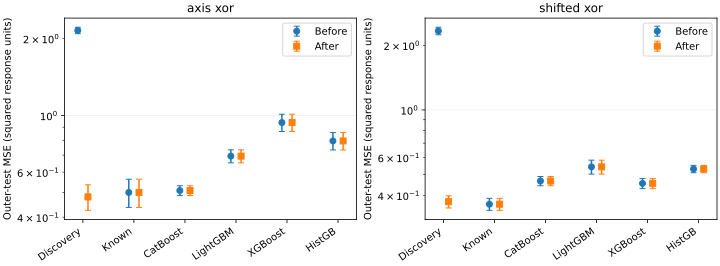

In [11]:
display(gap_table(after))
plot_diagnostics("recovered")
display(SVG(filename=str(DIRECTORY / "method_comparison.svg")))

## All-named-reference audit

The frozen primary comparison excludes Ridge from its four-tree winner selection. The benchmark guide also requires considering the strongest named method when a simpler method wins. This explicitly posthoc [reporting extension](interaction_capacity/REFERENCE_AUDIT.md) therefore admits all five competitors, preserving the primary analysis and its grading rule. Ridge wins the null process; the two null gaps are about −0.57%, rather than the larger advantage against CatBoost. All ten final point gaps remain at most +1%. This audit reuses outcomes and is not an independent experiment.

In [12]:
all_named = json.loads((DIRECTORY / "all_named_reference.json").read_text())["phases"]["recovered"]
display(GT(pd.DataFrame(all_named), rowname_col="task", groupname_col="track").tab_header(
    title="Gap to the retrospective best of all five named competitors",
    subtitle="Posthoc reference audit; paired percent gap and SE; negative favors mboostrs")
    .tab_spanner("Percent gap", ["gap_pct", "gap_se_pct"])
    .fmt_number(columns=["gap_pct", "gap_se_pct"], decimals=2)
    .tab_source_note("Ridge is eligible here. SE conditions on the retrospectively chosen complete winner and excludes winner-selection uncertainty. The predeclared four-tree analysis is retained separately."))

GT(_tbl_data=             task                track best_competitor  complete    gap_pct  \
0        axis_xor  known_specification        catboost      True  -1.953436   
1        axis_xor            discovery        catboost      True  -5.717914   
2     shifted_xor  known_specification         xgboost      True -20.011935   
3     shifted_xor            discovery         xgboost      True -17.772985   
4  smooth_product  known_specification        catboost      True -20.093109   
5  smooth_product            discovery        catboost      True -11.523405   
6        additive  known_specification        catboost      True  -8.291719   
7        additive            discovery        catboost      True  -7.945109   
8            null  known_specification           ridge      True  -0.567579   
9            null            discovery           ridge      True  -0.567579   

   gap_se_pct  within_1pct  
0   11.426653         True  
1    9.873504         True  
2    2.203476         True  
3    2.797733         True  
4    1.030621         True  
5    3.190738         True  
6    0.864412         True  
7    0.713367         True  
8    0.152993         True  
9    0.152993         True  , _body=<great_tables._gt_data.Body object at 0x12c787b30>, _boxhead=Boxhead([ColInfo(var='task', type=<ColInfoTypeEnum.stub: 2>, column_label='task', column_align='left', column_width=None), ColInfo(var='track', type=<ColInfoTypeEnum.row_group: 3>, column_label='track', column_align='left', column_width=None), ColInfo(var='best_competitor', type=<ColInfoTypeEnum.default: 1>, column_label='best_competitor', column_align='left', column_width=None), ColInfo(var='complete', type=<ColInfoTypeEnum.default: 1>, column_label='complete', column_align='center', column_width=None), ColInfo(var='gap_pct', type=<ColInfoTypeEnum.default: 1>, column_label='gap_pct', column_align='right', column_width=None), ColInfo(var='gap_se_pct', type=<ColInfoTypeEnum.default: 1>, column_label='gap_se_pct', column_align='right', column_width=None), ColInfo(var='within_1pct', type=<ColInfoTypeEnum.default: 1>, column_label='within_1pct', column_align='center', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x12c55f590>, _spanners=Spanners([SpannerInfo(spanner_id='Percent gap', spanner_level=0, spanner_label='Percent gap', spanner_units=None, spanner_pattern=None, vars=['gap_pct', 'gap_se_pct'], built=None)]), _heading=Heading(title='Gap to the retrospective best of all five named competitors', subtitle='Posthoc reference audit; paired percent gap and SE; negative favors mboostrs', preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x12c86d1c0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x12c5b8890>, _source_notes=['Ridge is eligible here. SE conditions on the retrospectively chosen complete winner and excludes winner-selection uncertainty. The predeclared four-tree analysis is retained separately.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x12c5b8230>, _formats=[<great_tables._gt_data.FormatInfo object at 0x12c46ca40>], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSys

## Paired improvement

The following table compares each mboostrs track with its own earlier result. It keeps the known and discovery tracks separate. The repaired known-null cell has no numerical before/after loss difference, because its baseline failed on every draw; its completed after-phase MSE is in the opening table.

In [13]:
paired = json.loads((DIRECTORY / "recovered_paired_improvement.json").read_text())
changes = pd.DataFrame(paired["changes"])
display(GT(changes, rowname_col="task", groupname_col="track").tab_header(
    title="Matched before/after changes", subtitle="Eight paired outer draws; negative changes favor the repair")
    .tab_spanner("MSE", ["before_mse", "after_mse", "change_mse", "change_se"])
    .tab_spanner("Percent change", ["change_pct", "change_pct_se"])
    .fmt_number(columns=["before_mse", "after_mse", "change_mse", "change_se"], decimals=4)
    .fmt_number(columns=["change_pct", "change_pct_se"], decimals=2)
    .tab_source_note("SE uses independent data draws, not inner folds. Counts include complete pairs only; the baseline failures remain explicit."))

GT(_tbl_data=             task                track  completed  before_mse  after_mse  \
0        axis_xor  known_specification          8    0.499867   0.499867   
1        axis_xor            discovery          8    2.152081   0.480313   
2     shifted_xor  known_specification          8    0.363753   0.363753   
3     shifted_xor            discovery          8    2.332739   0.373788   
4  smooth_product  known_specification          8    0.264775   0.264775   
5  smooth_product            discovery          8    0.323494   0.293156   
6        additive  known_specification          8    0.254706   0.254706   
7        additive            discovery          8    0.255700   0.255700   
8            null  known_specification          0         NaN        NaN   
9            null            discovery          8    0.245479   0.245479   

   change_mse  change_se  change_pct  change_pct_se  unchanged_predictions  
0    0.000000   0.000000    0.000000       0.000000                      8  
1   -1.671768   0.068235  -77.739628       2.360984                      0  
2    0.000000   0.000000    0.000000       0.000000                      8  
3   -1.958951   0.105280  -83.680354       1.509313                      0  
4    0.000000   0.000000    0.000000       0.000000                      8  
5   -0.030338   0.014026   -8.228127       3.811273                      4  
6    0.000000   0.000000    0.000000       0.000000                      8  
7    0.000000   0.000000    0.000000       0.000000                      8  
8         NaN        NaN         NaN            NaN                      0  
9    0.000000   0.000000    0.000000       0.000000                      8  , _body=<great_tables._gt_data.Body object at 0x12c5c8dd0>, _boxhead=Boxhead([ColInfo(var='task', type=<ColInfoTypeEnum.stub: 2>, column_label='task', column_align='left', column_width=None), ColInfo(var='track', type=<ColInfoTypeEnum.row_group: 3>, column_label='track', column_align='left', column_width=None), ColInfo(var='completed', type=<ColInfoTypeEnum.default: 1>, column_label='completed', column_align='right', column_width=None), ColInfo(var='before_mse', type=<ColInfoTypeEnum.default: 1>, column_label='before_mse', column_align='right', column_width=None), ColInfo(var='after_mse', type=<ColInfoTypeEnum.default: 1>, column_label='after_mse', column_align='right', column_width=None), ColInfo(var='change_mse', type=<ColInfoTypeEnum.default: 1>, column_label='change_mse', column_align='right', column_width=None), ColInfo(var='change_se', type=<ColInfoTypeEnum.default: 1>, column_label='change_se', column_align='right', column_width=None), ColInfo(var='change_pct', type=<ColInfoTypeEnum.default: 1>, column_label='change_pct', column_align='right', column_width=None), ColInfo(var='change_pct_se', type=<ColInfoTypeEnum.default: 1>, column_label='change_pct_se', column_align='right', column_width=None), ColInfo(var='unchanged_predictions', type=<ColInfoTypeEnum.default: 1>, column_label='unchanged_predictions', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x12c5c8200>, _spanners=Spanners([SpannerInfo(spanner_id='MSE', spanner_level=0, spanner_label='MSE', spanner_units=None, spanner_pattern=None, vars=['before_mse', 'after_mse', 'change_mse', 'change_se'], built=None), SpannerInfo(spanner_id='Percent change', spanner_level=0, spanner_label='Percent change', spanner_units=None, spanner_pattern=None, vars=['change_pct', 'change_pct_se'], built=None)]), _heading=Heading(title='Matched before/after changes', subtitle='Eight paired outer draws; negative changes favor the repair', preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x12c55c560>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x12c612a20>, _source_notes=['SE uses independent data draws, not inner folds. Counts include complete pairs only; the baseline failures remain explicit.'], _footnotes=[], _styles=[]

## Failures and regressions

A successful prediction does not imply that every optional discovery stage completed. The table separates primary process failures from refused refits and other optional-stage errors. The eight baseline null errors are ordinary Python exceptions (`empty x_data`), not interpreter aborts. The additional table displays every individual draw whose paired outer MSE increases; unchanged or improving draws remain in the raw records.

In [14]:
audit = json.loads((DIRECTORY / "recovered_validation.json").read_text())
display(GT(pd.DataFrame(audit["stage_counts"])).tab_header(
    title="Prediction completion and optional discovery stages",
    subtitle="Counts are per eight-draw process; optional errors stay in every decision log"))
regressions = pd.DataFrame(audit["individual_regressions"])
if regressions.empty:
    regressions = pd.DataFrame([{"result": "No individual paired MSE increase above 1e-12"}])
display(GT(regressions).tab_header(title="Individual regressions",
    subtitle="All positive paired changes; no successful-only filtering"))

GT(_tbl_data=       phase            task  successful_predictions  available_refits  \
0   baseline        axis_xor                       8                 8   
1   baseline     shifted_xor                       8                 8   
2   baseline  smooth_product                       8                 8   
3   baseline        additive                       8                 8   
4   baseline            null                       8                 0   
5  recovered        axis_xor                       8                 0   
6  recovered     shifted_xor                       8                 0   
7  recovered  smooth_product                       8                 7   
8  recovered        additive                       8                 8   
9  recovered            null                       8                 0   

   optional_errors  tree_models  
0                0            0  
1                0            0  
2                0            0  
3                0            0  
4                0            0  
5               16            8  
6               15            8  
7                2            1  
8                0            0  
9                0            0  , _body=<great_tables._gt_data.Body object at 0x12c530770>, _boxhead=Boxhead([ColInfo(var='phase', type=<ColInfoTypeEnum.default: 1>, column_label='phase', column_align='left', column_width=None), ColInfo(var='task', type=<ColInfoTypeEnum.default: 1>, column_label='task', column_align='left', column_width=None), ColInfo(var='successful_predictions', type=<ColInfoTypeEnum.default: 1>, column_label='successful_predictions', column_align='right', column_width=None), ColInfo(var='available_refits', type=<ColInfoTypeEnum.default: 1>, column_label='available_refits', column_align='right', column_width=None), ColInfo(var='optional_errors', type=<ColInfoTypeEnum.default: 1>, column_label='optional_errors', column_align='right', column_width=None), ColInfo(var='tree_models', type=<ColInfoTypeEnum.default: 1>, column_label='tree_models', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x12c5c8f50>, _spanners=Spanners([]), _heading=Heading(title='Prediction completion and optional discovery stages', subtitle='Counts are per eight-draw process; optional errors stay in every decision log', preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x12c612030>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x12c611c70>, _source_notes=[], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x12c6118e0>, _formats=[], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color

Individual regressions
All positive paired changes; no successful-only filtering
result
No individual paired MSE increase above 1e-12


## Scorecard profiles

D11 is scored separately for each process and information track against the prespecified Ridge reference. Score 3 requires positive paired improvement exceeding two Monte Carlo SEs; score 2 requires positive improvement; otherwise the score is 1. A failed mboostrs cell is scored 1. Eleven other dimensions remain unmeasured. These related synthetic processes and unequal searches provide no evidence for levels 4 or 5, and a predictive win earns no structure-discovery or uncertainty-calibration credit.

In [15]:
scores = pd.DataFrame([
    {"phase": phase, "process": g["task"], "track": g["track"],
     "D11": g["d11_score"], "completed": g["completed"],
     "Ridge minus mboost MSE": g["ridge_improvement"], "paired SE": g["ridge_improvement_se"]}
    for phase, summary in [("baseline", before), ("after", after)] for g in summary["gaps"]
])
display(GT(scores).tab_header(title="D11 evidence by process and track",
    subtitle="Scorecard 2.1; no aggregate; all other dimensions unmeasured")
    .fmt_number(columns=["Ridge minus mboost MSE", "paired SE"], decimals=4))

GT(_tbl_data=       phase         process                track  D11  completed  \
0   baseline        axis_xor  known_specification    3          8   
1   baseline        axis_xor            discovery    3          8   
2   baseline     shifted_xor  known_specification    3          8   
3   baseline     shifted_xor            discovery    3          8   
4   baseline  smooth_product  known_specification    3          8   
5   baseline  smooth_product            discovery    3          8   
6   baseline        additive  known_specification    3          8   
7   baseline        additive            discovery    3          8   
8   baseline            null  known_specification    1          0   
9   baseline            null            discovery    3          8   
10     after        axis_xor  known_specification    3          8   
11     after        axis_xor            discovery    3          8   
12     after     shifted_xor  known_specification    3          8   
13     after     shifted_xor            discovery    3          8   
14     after  smooth_product  known_specification    3          8   
15     after  smooth_product            discovery    3          8   
16     after        additive  known_specification    3          8   
17     after        additive            discovery    3          8   
18     after            null  known_specification    3          8   
19     after            null            discovery    3          8   

    Ridge minus mboost MSE  paired SE  
0                 8.771109   0.054152  
1                 7.118895   0.053531  
2                 8.361240   0.041164  
3                 6.392254   0.082356  
4                 1.559623   0.014124  
5                 1.500904   0.014442  
6                 0.784131   0.007994  
7                 0.783137   0.007749  
8                      NaN        NaN  
9                 0.001424   0.000380  
10                8.771109   0.054152  
11                8.790663   0.046589  
12                8.361240   0.041164  
13                8.351205   0.040053  
14                1.559623   0.014124  
15                1.531241   0.009480  
16                0.784131   0.007994  
17                0.783137   0.007749  
18                0.001424   0.000380  
19                0.001424   0.000380  , _body=<great_tables._gt_data.Body object at 0x12c88c800>, _boxhead=Boxhead([ColInfo(var='phase', type=<ColInfoTypeEnum.default: 1>, column_label='phase', column_align='left', column_width=None), ColInfo(var='process', type=<ColInfoTypeEnum.default: 1>, column_label='process', column_align='left', column_width=None), ColInfo(var='track', type=<ColInfoTypeEnum.default: 1>, column_label='track', column_align='left', column_width=None), ColInfo(var='D11', type=<ColInfoTypeEnum.default: 1>, column_label='D11', column_align='right', column_width=None), ColInfo(var='completed', type=<ColInfoTypeEnum.default: 1>, column_label='completed', column_align='right', column_width=None), ColInfo(var='Ridge minus mboost MSE', type=<ColInfoTypeEnum.default: 1>, column_label='Ridge minus mboost MSE', column_align='right', column_width=None), ColInfo(var='paired SE', type=<ColInfoTypeEnum.default: 1>, column_label='paired SE', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x12c7853a0>, _spanners=Spanners([]), _heading=Heading(title='D11 evidence by process and track', subtitle='Scorecard 2.1; no aggregate; all other dimensions unmeasured', preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x12c611e20>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x12c610140>, _source_notes=[], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x12c6133e0>, _formats=[<great_tables._gt_data.FormatInfo object at 0x12c7860f0>], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_capt

## Run records and reproduction

The committed phase JSON files contain every planned job, input/prediction digest, source/native identity, settings, warnings and complete discovery log. The runner executes each job in an isolated process with a 240-second timeout and retains failures. Each job uses one numerical thread. Suites and validation work shared the machine, so elapsed times are descriptive and do not measure D5 speed ratios.

The record below illustrates the fields before aggregation. The audit verifies exact replay of unchanged peers and known fits, and separately verifies diagnostic and confirmation replay. An initial provenance-only observer used system Python 3.13 and was excluded; all actual jobs and the corrected observer use the repository's Python 3.12 and the recorded worktree native extension.

In [16]:
raw = read_document("recovered_primary")
record = next(r for r in raw["results"] if r.get("task") == "axis_xor"
              and r.get("seed") == 0 and r.get("method") == "mboostrs_discover")
representative = {key: record[key] for key in
    ["task", "seed", "method", "mse", "input_digest", "prediction_digest", "_status"]}
representative.update(formula=record["evidence"]["formula"],
    stopping_iteration=record["evidence"]["mstop"],
    refit_available=record["evidence"]["refit_available"])
display(GT(pd.DataFrame([representative])).tab_header(
    title="One complete after-phase record", subtitle="MSE in squared response units; identities tie rows to the measured fit"))
print(json.dumps({key: audit[key] for key in audit if key != "individual_regressions" and key != "stage_counts"}, indent=2))

GT(_tbl_data=       task  seed             method       mse  \
0  axis_xor     0  mboostrs_discover  0.392383   

                                        input_digest  \
0  sha256:727f4f54d8677e7ab93adc6a6334fd7f6fcfbbb...   

                                   prediction_digest  _status  \
0  sha256:b2f7d5a29c6a743ab70fd7467be8f31e4b2d7af...  success   

                                             formula  stopping_iteration  \
0  bbs(x3, df=4.0) + bbs(x1, df=2.5, knots=5) + b...                  81   

   refit_available  
0            False  , _body=<great_tables._gt_data.Body object at 0x12c7853a0>, _boxhead=Boxhead([ColInfo(var='task', type=<ColInfoTypeEnum.default: 1>, column_label='task', column_align='left', column_width=None), ColInfo(var='seed', type=<ColInfoTypeEnum.default: 1>, column_label='seed', column_align='right', column_width=None), ColInfo(var='method', type=<ColInfoTypeEnum.default: 1>, column_label='method', column_align='left', column_width=None), ColInfo(var='mse', type=<ColInfoTypeEnum.default: 1>, column_label='mse', column_align='right', column_width=None), ColInfo(var='input_digest', type=<ColInfoTypeEnum.default: 1>, column_label='input_digest', column_align='left', column_width=None), ColInfo(var='prediction_digest', type=<ColInfoTypeEnum.default: 1>, column_label='prediction_digest', column_align='left', column_width=None), ColInfo(var='_status', type=<ColInfoTypeEnum.default: 1>, column_label='_status', column_align='left', column_width=None), ColInfo(var='formula', type=<ColInfoTypeEnum.default: 1>, column_label='formula', column_align='left', column_width=None), ColInfo(var='stopping_iteration', type=<ColInfoTypeEnum.default: 1>, column_label='stopping_iteration', column_align='right', column_width=None), ColInfo(var='refit_available', type=<ColInfoTypeEnum.default: 1>, column_label='refit_available', column_align='center', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x12c5b93a0>, _spanners=Spanners([]), _heading=Heading(title='One complete after-phase record', subtitle='MSE in squared response units; identities tie rows to the measured fit', preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x12cecd6a0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x12cecd820>, _source_notes=[], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x12cecda30>, _formats=[], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=

{
  "primary_before_success": 272,
  "primary_after_success": 280,
  "primary_planned_per_phase": 280,
  "repaired_null_failures": 8,
  "unchanged_peer_predictions": 200,
  "unchanged_known_predictions": 32,
  "unchanged_diagnostic_predictions": 32,
  "tree_phase_confirmation_replayed": 36,
  "promotion_gate_passed": true,
  "recovery_gate_passed": true,
  "fresh_recovery_controls_replayed": 36
}


To reproduce a phase, check out the source revision in its `*_library.json`, build a matching release extension with the repository interpreter, and run each suite with that environment:

```bash
PYTHONPATH=python:. .venv/bin/python -m benches.bench_interaction_capacity --phase baseline --suite primary
PYTHONPATH=python:. .venv/bin/python -m benches.bench_interaction_capacity --phase baseline --suite diagnostic
PYTHONPATH=python:. .venv/bin/python -m benches.bench_interaction_capacity --phase baseline --suite controls
```

Repeat the tree-only repair with `--phase after` and the final integrated revision with `--phase recovered`, preserving the protocol and using a distinct phase/cache. The intermediate candidate controls are retained separately. Run `benches.report_interaction_capacity` for each phase, then the reporting notebook with the repository Jupyter environment. [VALIDATION.md](interaction_capacity/VALIDATION.md) records the exact validation and review revisions.

## Interpretation and remaining work

The two dominant discovery gaps change from **+329.33% (SE 22.93 percentage points)** to **−5.72% (SE 9.87)** for the axis boundary, and from **+425.39% (SE 37.50)** to **−17.77% (SE 2.80)** for the shifted boundary. The reference is retrospective CatBoost for the axis process and retrospective XGBoost for the shifted process. The axis result remains unresolved at two SE; meeting the point target does not establish a one-percent population guarantee.

Relative to its own baseline, discovery MSE falls **77.74% (paired SE 2.36 points)** on the axis process and **83.68% (SE 1.51)** on the shifted process. Smooth-product discovery also improves; additive and null predictions replay exactly. All 200 competitor predictions and all 32 previously successful known-specification predictions replay exactly. The eight failed known-null jobs now complete. No individual primary paired MSE increases from baseline to final, or from the tree-only to recovered phase.

All ten final process/track cells meet the one-percent point criterion, including the audit that lets Ridge win. The supplied known-specification gaps are −1.95% (SE 11.43) for the axis boundary and −20.01% (SE 2.20) for the shifted boundary. These results show that the available tree learner can be competitive on these supplied pairs; they do not prove that all-column tree search or classification is competitive. The two independent control gates support the specific workflow changes, with their stated finite limits.

The results address two-variable IID step interactions with five predictors. They do not resolve the broader all-column-tree claim in [#608](https://github.com/fcela/mboostrs/issues/608), bike forecasting or cancer classification. More folds, different data sizes, many noise variables, higher-order interactions and valid tree-effect inference require separate studies. Remaining gaps stay open with their evidence; the benchmark program is not complete.